# 05 · Inferência no Raspberry Pi 5

**Ementa 05** · Os modelos estão em `modelos/` (notebook 04). Agora a pergunta é de engenharia: **a triagem completa cabe no orçamento do
dispositivo?** O edital fixa duas metas: **≤ 3 s por condição** e **≤ 512 MB de RAM por inferência**.

Este notebook roda no PC e serve de **ensaio** para a sessão presencial no Lab Maker (5 h): os mesmos scripts rodam no Pi
(`scripts/benchmark.py`, `scripts/medir_memoria.py`, `scripts/triar.py`) e os números de lá substituem os daqui. Você vai:
**(1)** ver o que precisa estar instalado no Pi (e o que não precisa); **(2)** medir latência por modelo, threads e acelerador;
**(3)** decompor o tempo da triagem completa, de uma captura de 12 MP ao laudo; **(4)** medir a memória num processo limpo;
**(5)** preparar o roteiro da sessão.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json, subprocess, sys, time
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_iae import dados as D, visualizacao as V
from retina_iae.inferencia import ModeloTFLite, runtime
from retina_iae.triagem import Triagem

V.configurar_estilo()
cfg = json.loads((D.MODELOS / "config_triagem.json").read_text(encoding="utf-8"))
AMOSTRAS = sorted((D.RAIZ / "amostras").glob("*.jpg"))
print("runtime:", runtime(), "| modelos:", {t: m["arquivo"] for t, m in cfg["modelos"].items()})
print("amostras:", [a.name for a in AMOSTRAS])

runtime: ai_edge_litert | modelos: {'rd': 'rd_efficientnet_lite0_int8.tflite', 'glaucoma': 'glaucoma_efficientnet_lite0_int8.tflite', 'dmri': 'dmri_efficientnet_lite0_int8.tflite'}
amostras: ['ddr_ilegivel_grau5.jpg', 'ddr_normal_grau0.jpg', 'ddr_rd_grau2.jpg', 'ddr_rd_grau4.jpg', 'rfmid_dmri.jpg', 'rfmid_normal.jpg']


## 1. O que vai para o Pi

No PC usamos o TensorFlow para **treinar e converter**. No Pi, só para **inferir**, bastam o LiteRT, NumPy, OpenCV e o `retina_pdi`
(`pi/requirements-pi.txt`). Comparando o espaço em disco das bibliotecas instaladas neste ambiente:

In [2]:
import importlib.util
def tamanho_pacote(nome):
    spec = importlib.util.find_spec(nome)
    pasta = Path(spec.origin).parent
    return sum(f.stat().st_size for f in pasta.rglob("*") if f.is_file()) / 1e6

pd.Series({p: tamanho_pacote(p) for p in ["tensorflow", "keras", "ai_edge_litert", "cv2", "numpy", "retina_pdi", "retina_iae"]},
          name="MB em disco").round(1).to_frame()

,MB em disco
tensorflow,1475.8
keras,25.1
ai_edge_litert,58.7
cv2,115.8
numpy,32.5
retina_pdi,0.1
retina_iae,0.1


O TensorFlow sozinho ocupa mais de 1 GB; o LiteRT, uma fração disso. Os três modelos int8 somam poucos MB. É essa separação
**treino (PC) × inferência (dispositivo)** que torna viável um retinógrafo de baixo custo.

## 2. Latência de cada modelo

Só o `invoke()` (a rede), com a imagem já pré-processada. Variamos o número de threads (o Pi 5 tem 4 núcleos Cortex-A76) e comparamos
com o modelo de RD nos outros formatos (`modelos/comparacao/`).

In [3]:
linhas = []
arquivos = [D.MODELOS / m["arquivo"] for m in cfg["modelos"].values()] + sorted((D.MODELOS / "comparacao").glob("rd_*.tflite"))
x = D.Cache()[D.carregar_particoes("rd").id.iloc[:1]]
for arq in arquivos:
    for th in (1, 2, 4):
        m = ModeloTFLite(arq, threads=th)
        lat = m.medir_latencia(x, repeticoes=40)
        linhas.append({"modelo": arq.name.replace(".tflite", ""), "grupo": arq.parent.name, "threads": th, "MB": m.tamanho_bytes / 1e6,
                       "XNNPACK": m.xnnpack, "mediana (ms)": lat["mediana_ms"], "p95 (ms)": lat["p95_ms"]})
lat = pd.DataFrame(linhas)
lat.pivot_table(index=["grupo", "modelo", "MB", "XNNPACK"], columns="threads", values="mediana (ms)").round(2)

threads                                                             1       2  \
grupo      modelo                           MB        XNNPACK                   
comparacao rd_efficientnet_lite0_dinamica   3.728824  True      41.28   43.58   
           rd_efficientnet_lite0_float16    6.790868  True      16.24    8.44   
           rd_efficientnet_lite0_float32    13.460924 True      16.29    8.40   
           rd_efficientnet_lite0_int8       3.979000  True       9.44    5.19   
           rd_mobilenetv3_small_dinamica    1.133696  True       5.76    3.68   
           rd_mobilenetv3_small_float16     1.948260  True       2.60    1.40   
           rd_mobilenetv3_small_float32     3.756524  True       2.60    1.44   
           rd_mobilenetv3_small_int8        1.240080  False    219.11  138.85   
modelos    dmri_efficientnet_lite0_int8     3.980400  True      10.83    6.48   
           glaucoma_efficientnet_lite0_int8 3.982264  True      11.20    6.17   
           rd_efficientnet_lite0_int8       3.979000  True      10.95    6.22   

threads                                                             4  
grupo      modelo                           MB        XNNPACK          
comparacao rd_efficientnet_lite0_dinamica   3.728824  True      79.89  
           rd_efficientnet_lite0_float16    6.790868  True       4.74  
           rd_efficientnet_lite0_float32    13.460924 True       4.74  
           rd_efficientnet_lite0_int8       3.979000  True       3.20  
           rd_mobilenetv3_small_dinamica    1.133696  True       7.18  
           rd_mobilenetv3_small_float16     1.948260  True       1.44  
           rd_mobilenetv3_small_float32     3.756524  True       1.55  
           rd_mobilenetv3_small_int8        1.240080  False    105.00  
modelos    dmri_efficientnet_lite0_int8     3.980400  True       4.04  
           glaucoma_efficientnet_lite0_int8 3.982264  True       3.97  
           rd_efficientnet_lite0_int8       3.979000  True       3.89

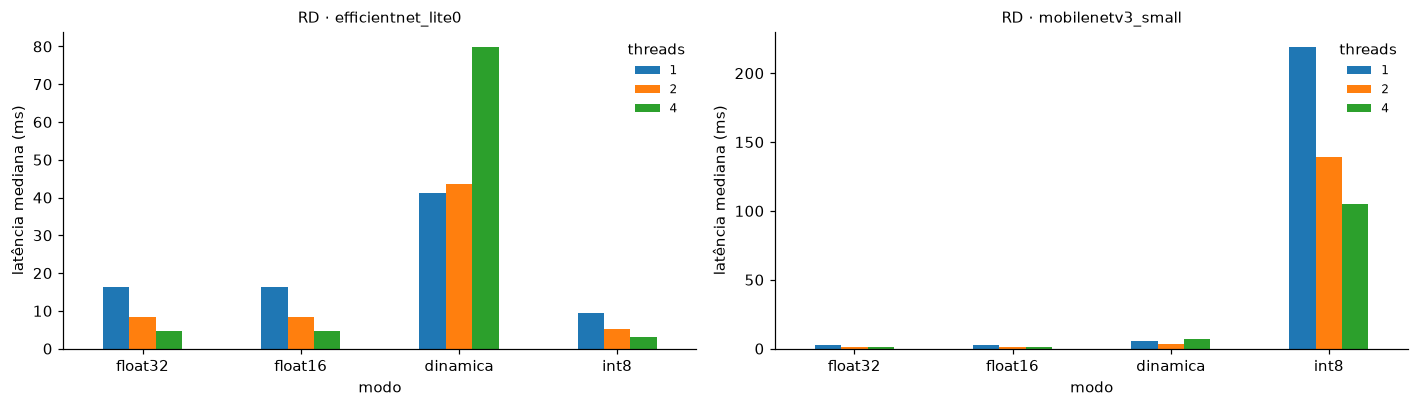

In [4]:
sel = lat[lat.grupo == "comparacao"].copy()
sel["arquitetura"] = sel.modelo.str.extract(r"rd_(.+)_(?:float32|float16|dinamica|int8)")[0]
sel["modo"] = sel.modelo.str.extract(r"_(float32|float16|dinamica|int8)$")[0]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for ax, (arq_, g) in zip(axs, sel.groupby("arquitetura")):
    g.pivot(index="modo", columns="threads", values="mediana (ms)").loc[["float32", "float16", "dinamica", "int8"]].plot.bar(ax=ax, rot=0)
    ax.set_title(f"RD · {arq_}"); ax.set_ylabel("latência mediana (ms)"); ax.legend(title="threads", frameon=False, fontsize=8)
fig.tight_layout(); V.salvar_figura(fig, "05_latencia_modos_threads"); plt.show()

Observe três coisas — e confira se elas se repetem no Pi:

1. **Threads:** de 1 para 4 o tempo cai, mas não 4×: parte do trabalho é sequencial e a memória é compartilhada.
2. **int8 com XNNPACK** é o formato mais rápido do Lite0 (≈ 3–4 ms). O MobileNetV3 int8, **sem** XNNPACK, leva ≈ 100 ms — dezenas de vezes mais que
   o próprio MobileNetV3 **float32** (≈ 1,5 ms, o mais rápido de todos). E a faixa **dinâmica** é lenta nas duas arquiteturas. "Menor" não é "mais rápido":
   quem decide é o runtime.
3. Em todos os casos, a rede leva **milissegundos** — duas a três ordens de grandeza abaixo da meta de 3 s.

## 3. A triagem completa: da captura ao laudo

No dispositivo, o modelo é a última etapa. Antes vêm a máscara do FOV, o **controle de qualidade** e a **preparação** do Módulo 02, que trabalham na
imagem em **resolução de captura**. O Módulo 02 trabalhou com capturas de 12 MP (4608×2592, exercício 1 do notebook 06); simulamos isso ampliando uma
imagem do DDR (o conteúdo fica "borrado", mas o **custo** de processar 12 MP é o real).

In [5]:
tri = Triagem(threads=4, exigir_qualidade=False)
base = D.carregar_rgb(AMOSTRAS[0])
resolucoes = {"1024 px (amostra)": base, "2048 px": cv2.resize(base, (2048, round(2048 * base.shape[0] / base.shape[1]))),
              "12 MP (4608×2592)": cv2.resize(base, (4608, 2592), interpolation=cv2.INTER_CUBIC)}
linhas = []
for nome, img in resolucoes.items():
    tri.avaliar(img)                                            # aquecimento
    tempos = pd.DataFrame([tri.avaliar(img).tempos_ms for _ in range(3)]).median()
    linhas.append({"captura": nome, **tempos.round(1).to_dict()})
etapas = pd.DataFrame(linhas).set_index("captura"); etapas

,fov,qualidade,preparacao,total,modelo_rd,modelo_glaucoma,modelo_dmri
captura,,,,,,,
1024 px (amostra),8.4,79.8,6.8,107.8,4.0,3.9,4.0
2048 px,10.3,110.3,24.7,158.3,4.2,4.3,4.0
12 MP (4608×2592),20.4,288.2,129.6,449.0,4.1,3.9,4.1


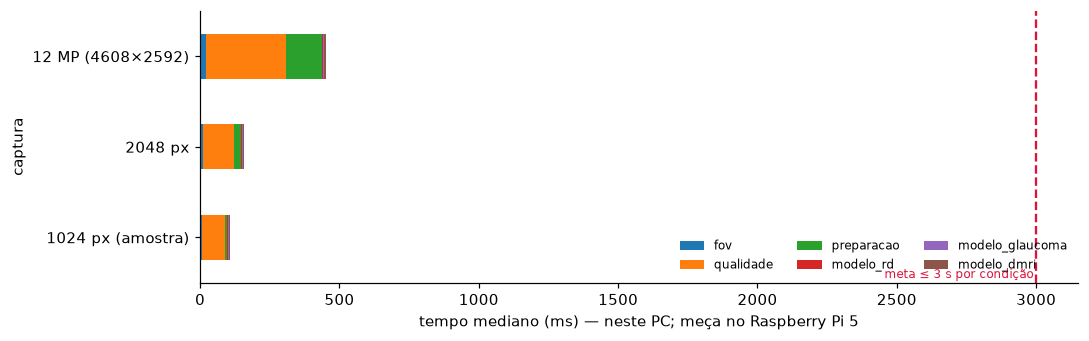

In [6]:
cols = [c for c in ["fov", "qualidade", "preparacao", "modelo_rd", "modelo_glaucoma", "modelo_dmri"] if c in etapas]
ax = etapas[cols].plot.barh(stacked=True, figsize=(10, 3.2))
ax.axvline(3000, color="crimson", ls="--"); ax.text(2990, -0.45, "meta ≤ 3 s por condição", color="crimson", ha="right", fontsize=8)
ax.set_xlabel("tempo mediano (ms) — neste PC; meça no Raspberry Pi 5"); ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower right")
plt.tight_layout(); V.salvar_figura(plt.gcf(), "05_tempo_etapas"); plt.show()

Com 12 MP, **o pré-processamento domina** — os três modelos juntos são uma fatia fina da barra. Daí a otimização sugerida no Módulo 02:
**reduzir a captura uma única vez** (≈ 1024 px) antes do FOV e da qualidade. O tensor final de 224 px quase não muda, porque ele já é uma redução
por média de área:

In [7]:
cap = resolucoes["12 MP (4608×2592)"]
t0 = time.perf_counter(); r_cheia = tri.avaliar(cap); t_cheia = (time.perf_counter() - t0) * 1e3
t0 = time.perf_counter()
reduzida = cv2.resize(cap, (1024, round(1024 * cap.shape[0] / cap.shape[1])), interpolation=cv2.INTER_AREA)
r_red = tri.avaliar(reduzida); t_red = (time.perf_counter() - t0) * 1e3
pd.DataFrame({"resolução cheia": {"tempo total (ms)": t_cheia, **{f"P({k})": v for k, v in r_cheia.probabilidades.items()}},
              "reduzida p/ 1024 px antes": {"tempo total (ms)": t_red, **{f"P({k})": v for k, v in r_red.probabilidades.items()}}}).round(3)

,resolução cheia,reduzida p/ 1024 px antes
tempo total (ms),433.627,111.986
P(rd),0.000,0.000
P(glaucoma),0.141,0.145
P(dmri),0.000,0.000


⚠️ Ao adotar essa otimização, os **limiares de qualidade** do Módulo 02 precisam ser recalibrados na nova resolução (o próprio Módulo 02 alertou),
e a **paridade** com o treino deve ser conferida: o cache de treino foi gerado a partir de imagens de até 1024 px, então reduzir para 1024 px no
dispositivo deixa treino e inferência **mais** parecidos, não menos.

## 4. Memória

Medir memória dentro deste notebook não serve: o kernel já carregou pandas, matplotlib e (nos notebooks anteriores) o TensorFlow. Rodamos a triagem num
**processo novo**, só com o que vai para o Pi (`scripts/medir_memoria.py`):

In [8]:
saida = subprocess.run([sys.executable, str(D.RAIZ / "scripts" / "medir_memoria.py"), *map(str, AMOSTRAS)],
                       capture_output=True, text=True, cwd=D.RAIZ)
mem = json.loads(saida.stdout.strip().splitlines()[-1])
pd.Series(mem, name="MB").to_frame()

,MB
inicio_MB,33.3
bibliotecas_MB,146.7
modelos_MB,184.3
apos_triagem_MB,218.4
pico_MB,218.4
imagens,6.0


O pico fica bem abaixo de 512 MB — e a maior parte é o **interpretador Python com NumPy/OpenCV/SciPy**, não os modelos (a diferença entre
`bibliotecas_MB` e `modelos_MB`). No Pi, os números absolutos mudam (ARM, outro alocador), mas a proporção se mantém.

## 5. Conferência das metas (neste PC)

In [9]:
pre = etapas.loc["12 MP (4608×2592)", ["fov", "qualidade", "preparacao"]].sum()
pior_modelo = etapas.loc["12 MP (4608×2592)", [c for c in etapas.columns if c.startswith("modelo_")]].max()
pd.DataFrame([
    {"meta do edital": "≤ 3 s por condição (captura 12 MP)", "medido no PC": f"{(pre + pior_modelo) / 1e3:.2f} s", "situação": "OK" if pre + pior_modelo <= 3000 else "ACIMA"},
    {"meta do edital": "≤ 512 MB de RAM por inferência", "medido no PC": f"{mem['pico_MB']:.0f} MB (pico do processo)", "situação": "OK" if mem["pico_MB"] <= 512 else "ACIMA"},
]).set_index("meta do edital")

,medido no PC,situação
meta do edital,,
≤ 3 s por condição (captura 12 MP),0.44 s,OK
≤ 512 MB de RAM por inferência,218 MB (pico do processo),OK


## 6. Roteiro da sessão presencial (Lab Maker · 5 h)

Detalhado em `docs/ROTEIRO_PI.md`. Em resumo:

| Tempo | Atividade | Comando |
|---|---|---|
| 0:00–0:40 | Preparar o Pi 5 (Raspberry Pi OS 64-bit, dissipador ativo), clonar o repositório e instalar | `git clone …/iae.git && cd iae && ./pi/setup_pi.sh` |
| 0:40–1:10 | Triagem das amostras e leitura do laudo | `.venv/bin/python scripts/triar.py amostras/*.jpg` |
| 1:10–2:10 | **Latência**: modelos × formatos × threads; anotar a temperatura | `.venv/bin/python scripts/benchmark.py` |
| 2:10–2:40 | **Memória** num processo limpo | `.venv/bin/python scripts/medir_memoria.py amostras/*.jpg` e `/usr/bin/time -v …` |
| 2:40–3:40 | **Estresse térmico**: 10 min de triagem contínua com e sem ventoinha; latência × temperatura | `scripts/benchmark.py --repeticoes 2000 --threads 4` |
| 3:40–4:30 | **Captura real** com o retinógrafo (Módulo 03) → triagem; qualidade reprovada? por quê? | `scripts/triar.py captura.jpg` |
| 4:30–5:00 | Consolidar a tabela e enviar os CSVs de `outputs/` ao fórum | — |

**Tabela a preencher (por equipe):**

| Medida | PC (este notebook) | Raspberry Pi 5 |
|---|---|---|
| latência int8 Lite0, 4 threads (ms) | | |
| latência int8 MobileNetV3, 4 threads (ms) | | |
| triagem completa, captura 12 MP (s) | | |
| triagem com redução prévia p/ 1024 px (s) | | |
| pico de memória (MB) | | |
| temperatura após 10 min (°C) | — | |

## Exercícios propostos

1. **Pi × PC.** Com os CSVs da sessão, calcule a razão Pi/PC para cada etapa. A razão é a mesma para o pré-processamento (OpenCV/SciPy) e para a
   rede (LiteRT/XNNPACK)? Por quê?
2. **Paralelismo entre modelos.** Os três modelos rodam em sequência. Rode-os em três *threads* Python com `threads=1` cada. O tempo total cai?
   (Dica: o `invoke()` libera o GIL.)
3. **Um modelo carregado por vez.** Se a RAM fosse de 256 MB, como você reorganizaria a triagem? Meça o custo de carregar um modelo (`carga_ms` no benchmark).
4. **Captura → laudo no protótipo.** Esboce o laço do software de aquisição: capturar (Picamera2), avaliar qualidade, pedir nova captura se reprovada
   (até 3 vezes), triar e salvar o laudo com data, hora e versão dos modelos (`config_triagem.json`).
5. **Acelerador externo.** O Raspberry Pi AI Kit (Hailo-8L) executa modelos int8 compilados para ele. Que restrições de operadores o modelo
   teria de respeitar? Isso favorece qual das duas arquiteturas?